# Robotic Knee & Hip Replacement – Part 2: Analysis
Continues from `cs4_01_download.ipynb`, which downloaded all 20,634 FDA reports for product code OLO, verified them against the FDA's own counts, and saved the 7,539 reports for Stryker Mako, Zimmer Biomet ROSA and J&J VELYS.

## Step 5 – Load the data and get a first overview
The saved file is reloaded and checked against the counts from notebook 1. Then, for each robot: number of reports, years covered, and the share of reports involving a patient injury or death.

**Important:** these are **counts of reports, not failure rates**. A robot used in more operations will have more reports. The FDA does not publish how many surgeries each robot performs.

In [2]:
# 5.1 Load the three-robot file, check it against notebook 1, and summarise each robot
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

BASE  = '/content/drive/MyDrive/robotic-knee-fda'
CLEAN = f'{BASE}/data/clean'
FIG   = f'{BASE}/figures'

def gate(condition, message):
    """Stop the notebook if a check fails; print a pass line if it succeeds."""
    if not condition:
        raise AssertionError('GATE FAILED: ' + message)
    print('GATE PASSED:', message)

EXPECTED = {'Stryker Mako': 4984, 'J&J VELYS': 2455, 'Zimmer Biomet ROSA': 100}   # from notebook 1

robots = pd.read_csv(f'{CLEAN}/robot_reports.csv', dtype={'report_key': str}, parse_dates=['date_received'])
robots = robots.fillna({'event_type': '', 'product_problems': '', 'patient_problems': '',
                        'event_text': '', 'mfr_text': '', 'brand': '', 'manufacturer': ''})

gate(len(robots) == sum(EXPECTED.values()), f'loaded {len(robots):,} reports, same as notebook 1')
gate(robots['system'].value_counts().to_dict() == EXPECTED, 'reports per robot match notebook 1 exactly')
gate(robots['report_key'].is_unique, 'report keys are unique')

robots['year'] = robots['date_received'].dt.year
summary = robots.groupby('system').agg(
    reports=('report_key', 'size'),
    first_year=('year', 'min'),
    last_year=('year', 'max'),
    injury_pct=('event_type', lambda s: (s == 'Injury').mean() * 100),
    death_n=('event_type', lambda s: (s == 'Death').sum()),
    malfunction_pct=('event_type', lambda s: (s == 'Malfunction').mean() * 100),
).sort_values('reports', ascending=False)

events = pd.crosstab(robots['system'], robots['event_type'])
gate(events.sum(axis=1).to_dict() == EXPECTED, 'event-type table adds up to each robot\'s total')

print('\n', summary.round(1).to_string())
print('\nEvent types per robot (counts):\n', events.to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GATE PASSED: loaded 7,539 reports, same as notebook 1
GATE PASSED: reports per robot match notebook 1 exactly
GATE PASSED: report keys are unique
GATE PASSED: event-type table adds up to each robot's total

                     reports  first_year  last_year  injury_pct  death_n  malfunction_pct
system                                                                                  
Stryker Mako           4984        2009       2026        14.8        0             85.1
J&J VELYS              2455        2021       2026         0.7        0             99.3
Zimmer Biomet ROSA      100        2019       2026        43.0        0             57.0

Event types per robot (counts):
 event_type             Injury  Malfunction  Other
system                                           
J&J VELYS           0      16         2439      0
Stryker Mako        2     736     

## Step 6 – What goes wrong, and what happens to the patient
Each FDA report lists standard problem terms from the FDA's official coding list, for the **device** (e.g. "Device Stops Intermittently") and for the **patient** (e.g. "Bone Fracture"). Because these are official codes, they are counted directly, without keyword rules.

- Percentages are **% of that robot's reports** (a report can list several problems, so they can add up to more than 100%).
- - Patient terms that mean *no harm or no usable information* ("No Patient Involvement", "No Known Impact or Consequence to Patient", "No Clinical Signs…", "Insufficient Information", "No Information", "No Code Available", "…Term/Code Not Available") are counted separately as **no patient harm reported**.

**Gates:** for every robot, reports *with* at least one coded term + reports *without* any term = that robot's total; every percentage is between 0 and 100.

In [4]:
# 6.1 Count the FDA's coded device problems and patient problems for each robot
import re

def terms_per_report(column):
    """One row per (report, term); a term is counted once per report."""
    t = robots[['report_key', 'system', column]].copy()
    t[column] = t[column].str.split('; ')
    t = t.explode(column)
    t = t[t[column].notna() & (t[column].str.strip() != '')]
    return t.drop_duplicates(['report_key', column])

NO_HARM = re.compile(r'^No Patient Involvement$|^No Known Impact|^No Clinical Signs|^Insufficient Information$'
                     r'|^No Consequences|^No Information$|^No Code Available$|Term/Code Not Available', re.I)

device_terms  = terms_per_report('product_problems')
patient_terms = terms_per_report('patient_problems')
patient_terms['no_harm'] = patient_terms['patient_problems'].str.contains(NO_HARM)

for system, total in EXPECTED.items():
    with_dev = device_terms.loc[device_terms['system'] == system, 'report_key'].nunique()
    without_dev = (robots.loc[robots['system'] == system, 'product_problems'].str.strip() == '').sum()
    gate(with_dev + without_dev == total, f'{system}: device-problem coverage adds up ({with_dev:,} + {without_dev:,} = {total:,})')

def top_terms(table, column, system, n=8):
    sub = table[table['system'] == system]
    counts = sub[column].value_counts().head(n)
    pct = counts / EXPECTED[system] * 100
    gate(pct.between(0, 100).all(), f'{system}: all percentages between 0 and 100')
    return pd.DataFrame({'reports': counts, '% of reports': pct.round(1)})

for system in EXPECTED:
    total = EXPECTED[system]
    harm = patient_terms[(patient_terms['system'] == system) & ~patient_terms['no_harm']]
    harmed_reports = harm['report_key'].nunique()
    print(f'\n================ {system}  ({total:,} reports) ================')
    print('\nTop device problems:')
    print(top_terms(device_terms, 'product_problems', system).to_string())
    print(f'\nReports describing an actual patient problem: {harmed_reports:,} ({harmed_reports / total * 100:.1f}%)')
    print('Top patient problems (excluding "no harm" terms):')
    print(top_terms(harm, 'patient_problems', system).to_string())

GATE PASSED: Stryker Mako: device-problem coverage adds up (4,955 + 29 = 4,984)
GATE PASSED: J&J VELYS: device-problem coverage adds up (2,452 + 3 = 2,455)
GATE PASSED: Zimmer Biomet ROSA: device-problem coverage adds up (98 + 2 = 100)

================ Stryker Mako  (4,984 reports) ================

Top device problems:
GATE PASSED: Stryker Mako: all percentages between 0 and 100
                                                       reports  % of reports
product_problems                                                            
Detachment of Device or Device Component                  1380          27.7
Mechanical Problem                                         703          14.1
Insufficient Device Problem Information                    656          13.2
Non Reproducible Results                                   432           8.7
Break                                                      419           8.4
Material Integrity Problem                                 376           7.5


## Step 7 – Group the patient problems into clinical categories
The FDA uses dozens of patient-problem terms. To compare the robots clearly, each term is placed in **one** clinical category, checked in this order (first match wins):

| Category | Keywords |
|---|---|
| Foreign body left in patient | foreign body, embedded |
| Implant loosening or failure | osseointegration, implant failure, osteolysis, collapse |
| Fracture or bone damage | fracture, notching, bone |
| Soft tissue, nerve or vessel injury | tissue, nerve, vascular, laceration, ligament, tendon, bleeding, haematoma, burn, thrombosis, embolism, aneurysm, rupture |
| Infection or wound problem | infection, wound, dehiscence, sepsis, abscess, impaired healing, blister |
| Joint instability, falls or mobility problems | dislocation, laxity, ambulation, posture, fall, limb length, impingement, weakness, paresis |
| Pain, stiffness or swelling | pain, discomfort, stiffness, range of motion, limited mobility, arthralgia, swelling, oedema, inflammation |

*Clinical review:* the first version of this step left dislocation, laxity, gait problems, falls and implant-fixation problems in "Other". On clinical review they were given their own categories, because they are central to post-operative rehabilitation.

Terms that match none of these go to **"Other or unspecified injury"** and are listed for clinical review.

**Gates:** every term gets exactly one category · for each robot, the reports in the categories are exactly the reports with a patient problem from Step 6.

In [6]:
# 7.1 Put each patient-problem term into one clinical category and compare the robots
CATEGORIES = [
    ('Foreign body left in patient',                  r'foreign body|embedded'),
    ('Implant loosening or failure',                  r'osseointegration|failure of implant|osteolysis|collapse'),
    ('Fracture or bone damage',                       r'fractur|notch|bone'),
    ('Soft tissue, nerve or vessel injury',           r'tissue|nerve|vascular|vessel|laceration|ligament|tendon|hemorrhag|haemorrhag|bleed|hematoma|haematoma|burn|dissection|perforat|thrombo|embol|aneurysm|rupture'),
    ('Infection or wound problem',                    r'infect|wound|dehiscence|sepsis|abscess|healing|blister'),
    ('Joint instability, falls or mobility problems', r'dislocat|laxity|ambulation|postural|\bfall|limb length|impingement|weakness|paresis'),
    ('Pain, stiffness or swelling',                   r'pain|discomfort|stiff|range of motion|limited mobility|arthralgia|swell|edema|oedema|inflammation'),
]
OTHER_HARM = 'Other or unspecified injury'

def clinical_category(term):
    for name, pattern in CATEGORIES:
        if re.search(pattern, term, re.I):
            return name
    return OTHER_HARM

harm = patient_terms[~patient_terms['no_harm']].copy()
harm['category'] = harm['patient_problems'].map(clinical_category)
gate(harm['category'].notna().all(), 'every patient-problem term has exactly one category')

for system, total in EXPECTED.items():
    harmed = harm.loc[harm['system'] == system, 'report_key'].nunique()
    in_categories = harm.loc[harm['system'] == system].groupby('category')['report_key'].apply(set)
    union = set().union(*in_categories) if len(in_categories) else set()
    gate(len(union) == harmed, f'{system}: categories cover exactly the {harmed:,} reports with a patient problem')

table = (harm.drop_duplicates(['report_key', 'category'])
             .pivot_table(index='category', columns='system', values='report_key', aggfunc='count', fill_value=0))
order = [c for c, _ in CATEGORIES] + [OTHER_HARM]
table = table.reindex([c for c in order if c in table.index])[list(EXPECTED)]
pct = (table / pd.Series(EXPECTED) * 100).round(1)

print('\nReports per clinical category (count):\n', table.to_string())
print('\nAs % of each robot\'s reports:\n', pct.to_string())

print('\nTerms placed in "Other or unspecified injury" (please review clinically):')
print(harm.loc[harm['category'] == OTHER_HARM, 'patient_problems'].value_counts().to_string())

GATE PASSED: every patient-problem term has exactly one category
GATE PASSED: Stryker Mako: categories cover exactly the 606 reports with a patient problem
GATE PASSED: J&J VELYS: categories cover exactly the 317 reports with a patient problem
GATE PASSED: Zimmer Biomet ROSA: categories cover exactly the 9 reports with a patient problem

Reports per clinical category (count):
 system                                         Stryker Mako  J&J VELYS  Zimmer Biomet ROSA
category                                                                                  
Foreign body left in patient                            145          1                   0
Implant loosening or failure                             23          0                   0
Fracture or bone damage                                  79        141                   4
Soft tissue, nerve or vessel injury                     107        182                   2
Infection or wound problem                               52          1    

*Note: 2 reports use the term "Not Applicable", which means no patient problem. They remain in "Other"; this does not change any finding.*

## Step 8 – Read the event descriptions behind the fracture reports
The coded terms show *that* a fracture or bone damage occurred; the free-text event description shows *how*. For every report in the "Fracture or bone damage" category, the description is searched for:
- **Pin / tracker-site fracture:** a fracture word (fracture, broke, break) **and** pin, tracker, array, checkpoint or bone screw
- **Notching:** notch (the saw cutting into the front of the femur)
- **Fracture found after surgery:** a fracture word **and** post-op, days/weeks/months later, fell/fall, rehab, physio, walking or ambulation

*Clinical review:* a first version without the fracture-word condition wrongly counted VELYS device names ("array clamp") as pin sites and matched reports with no injury. The fracture-word condition was added after reading the examples.

Three example descriptions are shown for each pattern so the keyword matches can be checked by reading them.

**Gates:** the fracture reports here are exactly the ones from Step 7 · no sub-group is larger than the fracture group.

In [8]:
# 8.1 Search the event descriptions of the fracture / bone-damage reports
fracture_keys = harm.loc[harm['category'] == 'Fracture or bone damage', 'report_key'].unique()
frac = robots[robots['report_key'].isin(fracture_keys)].copy()
gate(len(frac) == len(fracture_keys), f'{len(frac)} fracture / bone-damage reports, same as Step 7')

story = (frac['event_text'] + ' ' + frac['mfr_text']).str.lower()
fracture_word         = story.str.contains(r'fractur|\bbroke|\bbreak')
frac['pin_site']      = fracture_word & story.str.contains(r'\bpins?\b|pin (?:site|tract|hole)|tracker|array|checkpoint|bone screw')
frac['notching']      = story.str.contains(r'notch')
frac['after_surgery'] = fracture_word & story.str.contains(r'post.?op|(?:days?|weeks?|months?) (?:post|after|later)|\bfell\b|\bfall\b|rehab|physio|walking|ambulat')

summary8 = frac.groupby('system').agg(fracture_reports=('report_key', 'size'),
                                      pin_site=('pin_site', 'sum'),
                                      notching=('notching', 'sum'),
                                      found_after_surgery=('after_surgery', 'sum'))
gate(summary8[['pin_site', 'notching', 'found_after_surgery']].le(summary8['fracture_reports'], axis=0).all().all(),
     'no sub-group is larger than the fracture group')
print('\n', summary8.to_string())

def show_examples(mask, title, n=3):
    sub = frac[mask]
    print(f'\n--- {title} ({len(sub)} reports) – {min(n, len(sub))} examples ---')
    for _, r in sub.sample(min(n, len(sub)), random_state=1).iterrows():
        print(f'[{r["system"]}] {r["event_text"][:350]}\n')

show_examples((frac['system'] == 'Stryker Mako') & frac['pin_site'], 'Mako: pin / tracker site')
show_examples((frac['system'] == 'J&J VELYS') & frac['notching'], 'VELYS: notching')
show_examples(frac['after_surgery'], 'Any robot: found after surgery')

GATE PASSED: 224 fracture / bone-damage reports, same as Step 7
GATE PASSED: no sub-group is larger than the fracture group

                     fracture_reports  pin_site  notching  found_after_surgery
system                                                                       
J&J VELYS                        141         2        18                    1
Stryker Mako                      79        28         1                   34
Zimmer Biomet ROSA                 4         1         0                    1

--- Mako: pin / tracker site (28 reports) – 3 examples ---
[Stryker Mako] (B)(6) HAD A PATIENT RECEIVE A STRESS FRACTURE AT THE TIBIAL PIN SITE SIX MONTHS AGO AND IS STILL RECOVERING FROM IT. CASE TYPE: TKA. ADDITIONAL INFORMATION FROM MPS: HERE IS ALL THE INFORMATION I RECEIVED YESTERDAY REGARDING THE STRESS FRACTURE COMPLAINT: PATIENT IS 6 MONTH. POST OP, HAS STRESS FRACTURE AT TIBIAL PIN SITE. PATIENT IS STILL HEALING

[Stryker Mako] DURING DRILLING OF THE IN WOUND FEMORAL PI

## Step 9 – Save the result tables
The main results are saved as CSV files in `data/clean/`:
- `clinical_categories.csv` – reports per clinical category and robot (counts and %)
- `top_device_problems.csv` – the 8 most common device problems per robot
- `fracture_patterns.csv` – fracture reports per robot, with pin/tracker-site and found-after-surgery counts

**Gates:** each file is read back from Drive and must be identical to the table in the notebook.

In [9]:
# 9.1 Save the main result tables and prove each saved file is identical to the notebook table
saved_tables = {}

# Clinical categories: counts and % side by side
cat_out = table.add_suffix(' (n)').join(pct.add_suffix(' (%)')).reset_index()
saved_tables['clinical_categories.csv'] = cat_out

# Top 8 device problems per robot
dev_rows = []
for system in EXPECTED:
    top = device_terms.loc[device_terms['system'] == system, 'product_problems'].value_counts().head(8)
    for term, n in top.items():
        dev_rows.append({'system': system, 'device_problem': term, 'reports': n,
                         'pct_of_reports': round(n / EXPECTED[system] * 100, 1)})
saved_tables['top_device_problems.csv'] = pd.DataFrame(dev_rows)

# Fracture patterns
saved_tables['fracture_patterns.csv'] = summary8.reset_index()

for name, data in saved_tables.items():
    path = f'{CLEAN}/{name}'
    data.to_csv(path, index=False)
    back = pd.read_csv(path)
    gate(back.shape == data.shape, f'{name}: same rows and columns after saving {data.shape}')
    gate(back.astype(str).equals(data.reset_index(drop=True).astype(str)), f'{name}: every value identical after saving')

print('\nSaved files:', ', '.join(saved_tables))

GATE PASSED: clinical_categories.csv: same rows and columns after saving (8, 7)
GATE PASSED: clinical_categories.csv: every value identical after saving
GATE PASSED: top_device_problems.csv: same rows and columns after saving (24, 4)
GATE PASSED: top_device_problems.csv: every value identical after saving
GATE PASSED: fracture_patterns.csv: same rows and columns after saving (3, 5)
GATE PASSED: fracture_patterns.csv: every value identical after saving

Saved files: clinical_categories.csv, top_device_problems.csv, fracture_patterns.csv


## Step 10 – Charts
All charts use the same theme and are saved as PNG files (200 dpi) in `figures/`.

### Chart 10.1 – What happened to patients
Reports per clinical category (from Step 7) for Stryker Mako and J&J VELYS. Zimmer Biomet ROSA is not charted: it has only 9 category mentions, too few to show a pattern.

**Gate:** the numbers drawn in the chart equal the saved table exactly.

GATE PASSED: Stryker Mako: chart numbers equal the saved table
GATE PASSED: J&J VELYS: chart numbers equal the saved table
Saved figures/10_1_patient_problems_by_category.png


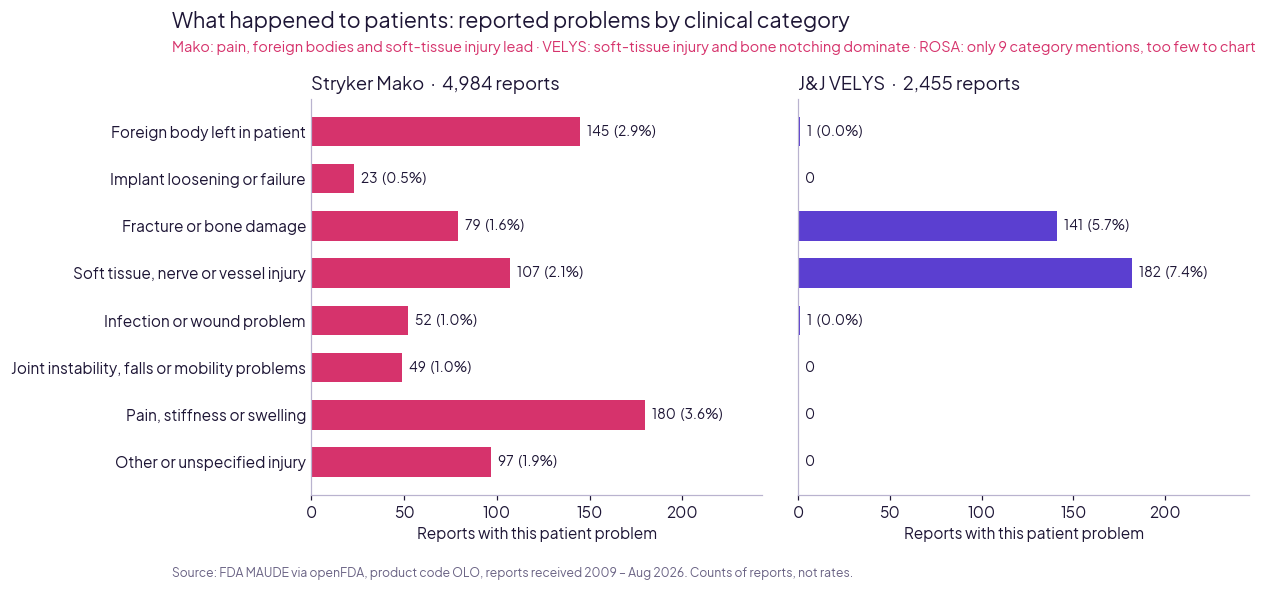

In [10]:
# 10.1 Chart theme, save helper, and chart 1: patient problems by clinical category
import matplotlib.pyplot as plt
from matplotlib import font_manager
import urllib.request, os
os.makedirs(FIG, exist_ok=True)

try:                                                    # expo theme font, default font if download fails
    font_path = '/content/PlusJakartaSans.ttf'
    urllib.request.urlretrieve('https://github.com/google/fonts/raw/main/ofl/plusjakartasans/PlusJakartaSans%5Bwght%5D.ttf', font_path)
    font_manager.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=font_path).get_name()
except Exception:
    print('Theme font not loaded, using default font')

PURPLE, VIOLET, BLUE, PINK = '#3B1E8C', '#5B3FD0', '#4C7BF5', '#D6336C'
GREY, INK, MUTED = '#B9B3CF', '#1E1636', '#6B6485'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GREY,
                     'axes.labelcolor': INK, 'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
                     'font.size': 10, 'figure.dpi': 110})
SOURCE = 'Source: FDA MAUDE via openFDA, product code OLO, reports received 2009 – Aug 2026. Counts of reports, not rates.'

def save_fig(fig, name):
    fig.text(0.01, 0.005, SOURCE, fontsize=8, color=MUTED, ha='left', va='bottom')
    fig.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight', facecolor='white')
    print('Saved figures/' + name + '.png')

show = ['Stryker Mako', 'J&J VELYS']
cats = table.index.tolist()[::-1]                      # reversed so the first category is on top
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={'wspace': 0.08})
drawn = {}
for ax, system, colour in zip(axes, show, [PINK, VIOLET]):
    vals = table.loc[cats, system]
    drawn[system] = vals
    bars = ax.barh(cats, vals, color=colour, height=0.62)
    for b, v in zip(bars, vals):
        ax.text(v + vals.max() * 0.02, b.get_y() + b.get_height() / 2,
                f'{v}  ({v / EXPECTED[system] * 100:.1f}%)' if v else '0', va='center', fontsize=9)
    ax.set_xlim(0, vals.max() * 1.35)
    ax.set_title(f'{system}  ·  {EXPECTED[system]:,} reports', fontsize=12)
    ax.set_xlabel('Reports with this patient problem')
    ax.tick_params(axis='y', length=0)

saved = pd.read_csv(f'{CLEAN}/clinical_categories.csv').set_index('category')
for system in show:
    gate(drawn[system].to_dict() == saved.loc[cats, f'{system} (n)'].to_dict(), f'{system}: chart numbers equal the saved table')

fig.suptitle('What happened to patients: reported problems by clinical category', x=0.01, ha='left',
             fontsize=14, fontweight='bold', y=1.04)
fig.text(0.01, 0.965, 'Mako: pain, foreign bodies and soft-tissue injury lead · VELYS: soft-tissue injury and bone notching dominate '
                      f'· ROSA: only {int(table["Zimmer Biomet ROSA"].sum())} category mentions, too few to chart',
         fontsize=9.5, color=PINK, ha='left')
fig.subplots_adjust(bottom=0.16)
save_fig(fig, '10_1_patient_problems_by_category')
plt.show()

### Chart 10.2 – Stryker Mako: pin-site fractures, often found after surgery
Breakdown of Mako's fracture / bone-damage reports (Step 8): how many describe a fracture at a pin or tracker site, how many were found after surgery, and how many were both. The subtitle quotes the timing from real report descriptions.

**Why this matters clinically:** the robot's trackers are fixed with pins in the femur and tibia (or the pelvis for hips). Fractures through these pin sites can appear days to months later, when the patient is walking, loading the leg and in rehabilitation.

**Gates:** the chart numbers equal the Step 8 table · the "both" group is not larger than either of its two groups.

GATE PASSED: chart numbers equal the Step 8 table
GATE PASSED: "both" group (14) is not larger than either group
Saved figures/10_2_mako_pin_site_fractures.png


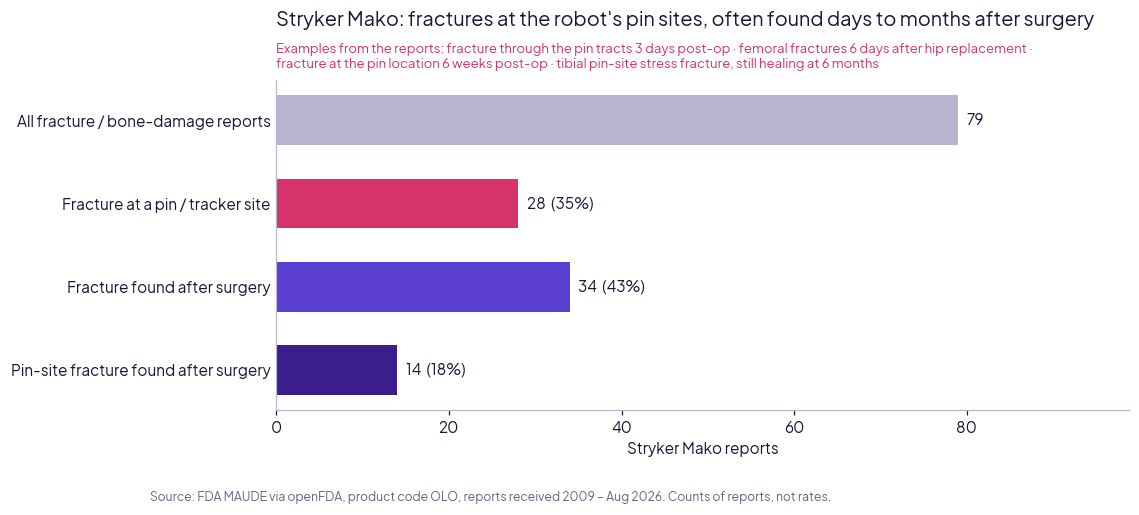

In [11]:
# 10.2 Chart 2: Mako fracture reports – pin/tracker site and found after surgery
mako = frac[frac['system'] == 'Stryker Mako']
mako_tot   = len(mako)
mako_pin   = int(mako['pin_site'].sum())
mako_after = int(mako['after_surgery'].sum())
mako_both  = int((mako['pin_site'] & mako['after_surgery']).sum())

row = summary8.loc['Stryker Mako']
gate([mako_tot, mako_pin, mako_after] == [row['fracture_reports'], row['pin_site'], row['found_after_surgery']],
     'chart numbers equal the Step 8 table')
gate(mako_both <= min(mako_pin, mako_after), f'"both" group ({mako_both}) is not larger than either group')

labels  = ['All fracture / bone-damage reports', 'Fracture at a pin / tracker site',
           'Fracture found after surgery', 'Pin-site fracture found after surgery']
values  = [mako_tot, mako_pin, mako_after, mako_both]
colours = [GREY, PINK, VIOLET, PURPLE]

fig, ax = plt.subplots(figsize=(10, 4.4))
bars = ax.barh(labels[::-1], values[::-1], color=colours[::-1], height=0.6)
for b, v in zip(bars, values[::-1]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2,
            f'{v}  ({v / mako_tot * 100:.0f}%)' if v != mako_tot else f'{v}',
            va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, mako_tot * 1.25)
ax.set_xlabel('Stryker Mako reports')
ax.tick_params(axis='y', length=0)
ax.set_title("Stryker Mako: fractures at the robot's pin sites, often found days to months after surgery", pad=36, fontsize=13)
ax.text(0, 1.04, 'Examples from the reports: fracture through the pin tracts 3 days post-op · femoral fractures 6 days after hip replacement ·\n'
                 'fracture at the pin location 6 weeks post-op · tibial pin-site stress fracture, still healing at 6 months',
        transform=ax.transAxes, fontsize=8.6, color=PINK)
fig.subplots_adjust(bottom=0.2)
save_fig(fig, '10_2_mako_pin_site_fractures')
plt.show()

## Step 11 – Key findings

**1. Scope.** Of 20,634 FDA reports for product code OLO (2009 – Aug 2026), **7,539** concern the three joint-replacement robots: Stryker Mako 4,984 · J&J VELYS 2,455 · Zimmer Biomet ROSA 100. Every count was verified against the FDA's own totals.

**2. No deaths.** None of the 7,539 reports for the three robots records a death.

**3. About 1 in 8 reports describes an actual patient problem** (Mako 12.2%, VELYS 12.9%, ROSA 9.0%). Most reports are device malfunctions without patient harm.

**4. Stryker Mako – parts, pain and pin sites.** The most common device problem is a part detaching (28% of reports), linked to **foreign bodies left in patients** (145 reports). The largest patient category is **pain, stiffness or swelling** (180).

**5. Mako pin-site fractures appear after surgery.** Of 79 Mako fracture / bone-damage reports, **28 (35%)** describe a fracture at a pin or tracker site and **34 (43%)** a fracture found after surgery – days to months later, while patients are walking and in rehabilitation (14 reports are both).

**6. J&J VELYS – the saw slipping.** "Device slipped" appears in **58%** of VELYS reports. Its patient problems are **soft-tissue injury (182)** and **bone damage (141)**, mostly **notching** of the femur during cutting – a known risk factor for later fractures above the knee implant.

**7. Zimmer Biomet ROSA – too few reports** (100, of which 9 describe a patient problem) to show a pattern.

### What this means for rehabilitation
- After robotic knee or hip replacement, **localised pain at the pin sites** during early loading should be checked rather than assumed to be normal post-operative pain.
- **Weight-bearing should be progressed carefully**, especially in patients with weaker bone, and **fall prevention** is part of fracture prevention.
- Where the surgeon reports **femoral notching**, the rehab team should know, because it raises the risk of a fracture above the implant.

### Limitations
- **Counts, not rates:** the FDA does not publish how many operations each robot performs, so the robots cannot be ranked by safety.
- MAUDE reports are **unverified and incomplete**: not every event is reported, and companies report differently (e.g. VELYS reports many small part malfunctions).
- **ROSA is a minimum:** some Zimmer accessory reports could not be attributed to ROSA.
- Pin-site and after-surgery patterns come from **keyword searches of report text**, checked by reading examples, not from a validated coding system.

In [12]:
# 11.1 Recalculate every headline number from the data (so the README and one-pager match the notebook)
harmed = {s: harm.loc[harm['system'] == s, 'report_key'].nunique() for s in EXPECTED}
mako_dev = device_terms[device_terms['system'] == 'Stryker Mako']['product_problems'].value_counts()
velys_dev = device_terms[device_terms['system'] == 'J&J VELYS']['product_problems'].value_counts()

facts = {
    'Robot reports (Mako / VELYS / ROSA)': f"{len(robots):,}  ({' / '.join(f'{v:,}' for v in EXPECTED.values())})",
    'Deaths reported':                     int((robots['event_type'] == 'Death').sum()),
    'Actual patient problem, Mako':        f"{harmed['Stryker Mako']} ({harmed['Stryker Mako'] / EXPECTED['Stryker Mako'] * 100:.1f}%)",
    'Actual patient problem, VELYS':       f"{harmed['J&J VELYS']} ({harmed['J&J VELYS'] / EXPECTED['J&J VELYS'] * 100:.1f}%)",
    'Actual patient problem, ROSA':        f"{harmed['Zimmer Biomet ROSA']} ({harmed['Zimmer Biomet ROSA'] / EXPECTED['Zimmer Biomet ROSA'] * 100:.1f}%)",
    'Mako: part detached':                 f"{mako_dev['Detachment of Device or Device Component'] / EXPECTED['Stryker Mako'] * 100:.0f}% of reports",
    'Mako: foreign body in patient':       int(table.loc['Foreign body left in patient', 'Stryker Mako']),
    'Mako: pain, stiffness or swelling':   int(table.loc['Pain, stiffness or swelling', 'Stryker Mako']),
    'Mako fractures: total / pin site / after surgery / both':
                                           f'{mako_tot} / {mako_pin} ({mako_pin / mako_tot * 100:.0f}%) / {mako_after} ({mako_after / mako_tot * 100:.0f}%) / {mako_both}',
    'VELYS: device slipped':               f"{velys_dev['Device Slipped'] / EXPECTED['J&J VELYS'] * 100:.0f}% of reports",
    'VELYS: soft tissue / bone damage':    f"{table.loc['Soft tissue, nerve or vessel injury', 'J&J VELYS']} / {table.loc['Fracture or bone damage', 'J&J VELYS']}",
}
gate(facts['Deaths reported'] == 0, 'no deaths among the three robots, as stated in finding 2')
gate(sum(EXPECTED.values()) == len(robots), 'robot report total matches finding 1')

for k, v in facts.items():
    print(f'{k:<58} {v}')

GATE PASSED: no deaths among the three robots, as stated in finding 2
GATE PASSED: robot report total matches finding 1
Robot reports (Mako / VELYS / ROSA)                        7,539  (4,984 / 2,455 / 100)
Deaths reported                                            0
Actual patient problem, Mako                               606 (12.2%)
Actual patient problem, VELYS                              317 (12.9%)
Actual patient problem, ROSA                               9 (9.0%)
Mako: part detached                                        28% of reports
Mako: foreign body in patient                              145
Mako: pain, stiffness or swelling                          180
Mako fractures: total / pin site / after surgery / both    79 / 28 (35%) / 34 (43%) / 14
VELYS: device slipped                                      59% of reports
VELYS: soft tissue / bone damage                           182 / 141
